<a href="https://colab.research.google.com/github/prabhnoor14/walmart-hurricane-project/blob/main/notebooks/team_notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!git clone https://github.com/prabhnoor14/walmart-hurricane-project

Cloning into 'walmart-hurricane-project'...
remote: Enumerating objects: 159, done.
remote: Counting objects: 100% (159/159), done.
remote: Compressing objects: 100% (154/154), done.
remote: Total 159 (delta 74), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (159/159), 1.12 MiB | 4.55 MiB/s, done.
Resolving deltas: 100% (74/74), done.


In [2]:
Decisions = []

def log_decision( decision, row_affected):
  Decisions.append({'decision': decision, 'rows': row_affected})
  print(f'{decision}({row_affected} row(s))')
def show_log():
  return pd.DataFrame(Decisions)

In [3]:
import pandas as pd

def load_table(PATH):
  try:
      df = pd.read_csv(PATH)
      df.head()
      return df
  except FileNotFoundError:
      print('File not found. Please check the file exist or double check the path')
      return None

In [4]:
def table_info(df):
  print('\nTable infor:')
  df.info()
  print('\nNull values for each column \n')
  print(df.isna().sum())                  # missing values per column
  print('\nDuplicated Rows Count: ',df.duplicated().sum())           # fully identical rows


In [5]:
walmart_transactions = load_table('/content/walmart-hurricane-project/data/walmart_transactions.csv')
table_info(walmart_transactions)


Table infor:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25562 entries, 0 to 25561
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   transaction_id  25562 non-null  object
 1   store_id        25562 non-null  object
 2   timestamp       24676 non-null  object
 3   sku             25562 non-null  object
 4   product_name    25562 non-null  object
 5   category        25562 non-null  object
 6   quantity        25562 non-null  int64 
 7   unit_price      25562 non-null  object
dtypes: int64(1), object(7)
memory usage: 1.6+ MB

Null values for each column 

transaction_id      0
store_id            0
timestamp         886
sku                 0
product_name        0
category            0
quantity            0
unit_price          0
dtype: int64

Duplicated Rows Count:  30


In [6]:
distribution_centers = load_table('/content/walmart-hurricane-project/data/distribution_centers.csv')
table_info(distribution_centers)


Table infor:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 8 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   dc_id                   5 non-null      object 
 1   dc_name                 5 non-null      object 
 2   city                    5 non-null      object 
 3   state                   5 non-null      object 
 4   avg_daily_shipments     5 non-null      int64  
 5   surge_capacity          5 non-null      object 
 6   distance_to_orlando_mi  5 non-null      int64  
 7   cost_per_shipment       4 non-null      float64
dtypes: float64(1), int64(2), object(5)
memory usage: 452.0+ bytes

Null values for each column 

dc_id                     0
dc_name                   0
city                      0
state                     0
avg_daily_shipments       0
surge_capacity            0
distance_to_orlando_mi    0
cost_per_shipment         1
dtype: int64

Duplicated Rows Coun

In [7]:
store_locations = load_table('/content/walmart-hurricane-project/data/store_locations.csv')
table_info(store_locations)


Table infor:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14 entries, 0 to 13
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   store_id    14 non-null     object 
 1   store_name  14 non-null     object 
 2   city        14 non-null     object 
 3   state       14 non-null     object 
 4   zip_code    14 non-null     int64  
 5   latitude    13 non-null     float64
 6   longitude   13 non-null     float64
 7   region      14 non-null     object 
dtypes: float64(2), int64(1), object(5)
memory usage: 1.0+ KB

Null values for each column 

store_id      0
store_name    0
city          0
state         0
zip_code      0
latitude      1
longitude     1
region        0
dtype: int64

Duplicated Rows Count:  0


In [8]:
product_catalog = load_table('/content/walmart-hurricane-project/data/product_catalog.csv')
table_info(product_catalog)


Table infor:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45 entries, 0 to 44
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sku           45 non-null     object 
 1   product_name  45 non-null     object 
 2   category      45 non-null     object 
 3   subcategory   32 non-null     object 
 4   unit_cost     40 non-null     float64
 5   supplier      45 non-null     object 
 6   package_size  45 non-null     object 
dtypes: float64(1), object(6)
memory usage: 2.6+ KB

Null values for each column 

sku              0
product_name     0
category         0
subcategory     13
unit_cost        5
supplier         0
package_size     0
dtype: int64

Duplicated Rows Count:  0


In [9]:
def drop_duplicate(frame):
  clean = frame.drop_duplicates().copy() # saving a copy of the frame after dropping duplicates to not alter the original frame
  print('rows:', len(frame), '->', len(clean))
  return clean

In [10]:
print('Count of rows after dropping duplicated rows from the product_catalog table')
product_catalog_copy = drop_duplicate(product_catalog)
print('Count of rows after dropping duplicated rows from the walmart_transactions table')
walmart_transactions_copy = drop_duplicate(walmart_transactions)
print('Count of rows after dropping duplicated rows from the distribution_centers table')
distribution_centers_copy = drop_duplicate(distribution_centers)
print('Count of rows after dropping duplicated rows from the store_location table')
store_locations_copy = drop_duplicate(store_locations)

Count of rows after dropping duplicated rows from the product_catalog table
rows: 45 -> 45
Count of rows after dropping duplicated rows from the walmart_transactions table
rows: 25562 -> 25532
Count of rows after dropping duplicated rows from the distribution_centers table
rows: 5 -> 5
Count of rows after dropping duplicated rows from the store_location table
rows: 14 -> 14


In [11]:
def transform_price_columns(df, column_name):
  df[column_name] = (df[column_name].astype(str)
                     .str.replace('$','',regex=False)
                     .str.strip().astype(float))
  return df

In [12]:
transform_price_columns(walmart_transactions_copy, 'unit_price')

,transaction_id,store_id,timestamp,sku,product_name,category,quantity,unit_price
0,TXN012636,FL-710,2024-09-24T09:48:13,PNUTBTR-16,PEANUT BUTTER,Grocery,1,3.15
1,TXN000759,fl-412,2024-09-13 20:30:20,CNSOUP-01,CANNED SOUP,GROCERY,1,2.02
2,TXN003338,FL-105,2024-09-17 10:06:00,TOILETPAPER12,Toilet Paper 12-Roll,Household Essentials,2,10.47
3,TXN025020,FL-330,2024-09-11 06:29:08,ROKU-STD,Roku Streaming Stick,ELECTRONICS,1,28.59
4,TXN015797,FL-302,2024-09-26 15:59:42,BEER-24,Light Beer 24pk,Alcoholic Beverages,3,18.82
...,...,...,...,...,...,...,...,...
25557,TXN020201,FL-105,2024-09-03T18:28:07,DIAPERS-3,Diapers Size 3,baby,2,24.32
25558,TXN014835,FL-239,09-26-2024 08:47:08,CARDS-01,Playing Cards,Games & Entertainment,3,5.00
25559,TXN002434,fl-239,16-Sep-2024 16:39,PAPERTOWEL6,Paper Towels 6-Roll,household,2,7.78
25560,TXN014739,FL-710,2024-09-25 17:08:35,CHRG-PORT,PORTABLE CHARGER,electronics,1,24.18


**Handling Timestamp**

In [13]:
walmart_transactions_copy['timestamp'] = pd.to_datetime(walmart_transactions_copy['timestamp'],errors='coerce', format ='mixed')
missing_date = walmart_transactions_copy['timestamp'].isna().sum()
print('count failed timestamps :',missing_date)

walmart_transactions_copy['hour'] = walmart_transactions_copy['timestamp'].dt.hour
walmart_transactions_copy[walmart_transactions_copy['timestamp'].isna()]

walmart_transactions_copy['transaction_date'] = (walmart_transactions_copy['timestamp'].dt.date)

walmart_transactions_copy['transaction_date'] = pd.to_datetime(walmart_transactions_copy['transaction_date'], errors ='coerce',format='mixed')

log_decision('Added a date column so that transactions can be grouped by dates for the analysis portion',len(walmart_transactions_copy['timestamp']))

count failed timestamps : 884
Added a date column so that transactions can be grouped by dates for the analysis portion(25532 row(s))


In [14]:
table_info(walmart_transactions_copy)


Table infor:
<class 'pandas.core.frame.DataFrame'>
Index: 25532 entries, 0 to 25561
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   transaction_id    25532 non-null  object        
 1   store_id          25532 non-null  object        
 2   timestamp         24648 non-null  datetime64[ns]
 3   sku               25532 non-null  object        
 4   product_name      25532 non-null  object        
 5   category          25532 non-null  object        
 6   quantity          25532 non-null  int64         
 7   unit_price        25532 non-null  float64       
 8   hour              24648 non-null  float64       
 9   transaction_date  24648 non-null  datetime64[ns]
dtypes: datetime64[ns](2), float64(2), int64(1), object(5)
memory usage: 2.1+ MB

Null values for each column 

transaction_id        0
store_id              0
timestamp           884
sku                   0
product_name          0
ca

**Handling NaN for the cost_per_shipment**

In [15]:
distribution_centers_copy

,dc_id,dc_name,city,state,avg_daily_shipments,surge_capacity,distance_to_orlando_mi,cost_per_shipment
0,DC-JAX,Jacksonville Distribution Center,Jacksonville,FL,500,1000,141,245.0
1,DC-ATL,Atlanta Distribution Center,Atlanta,GA,400,700,438,412.5
2,DC-DAL,Dallas Distribution Center,Dallas,TX,300,600,1108,687.0
3,DC-MIA,Miami Distribution Center,Miami,FL,350,~750,235,298.0
4,DC-BHM,Birmingham Distribution Center,Birmingham,AL,250,500,503,NaN


In [16]:
missing_cost_per_shipment =  distribution_centers_copy['cost_per_shipment'].isna().sum()
distribution_centers_copy['cost_per_shipment'] = distribution_centers_copy['cost_per_shipment'].fillna(distribution_centers_copy['cost_per_shipment'].median())
log_decision('Filling missing values in cost per shipment column with the median of all cost of shipments',missing_cost_per_shipment)

Filling missing values in cost per shipment column with the median of all cost of shipments(1 row(s))


**Handling NaN for the latitude and longitute**

**Handling NaN for the subcategory**

In [17]:
product_catalog_copy_with_na_sum = len(product_catalog_copy[product_catalog_copy['subcategory'].isna()])

SUBC_MAP = {
    'pop-tarts strawberry': 'Pop-Tarts',
    'Pop-Tarts Strawberry': 'Pop-Tarts',
    'Water - 24 Pack': 'Bottled',
    'FLASHLIGHT LED':'Flashlight',
    'Light Beer (24-pack)':'Light',
    'Monopoly Board Game':'Playing',
    'Board Game - Monopoly': 'Playing',
    'Canned Soup':'Canned',
    'First Aid Kit':'First',
    'PORTABLE CHARGER':'Portable',
    'Baby Formula':'Baby',
    'Heavy Duty Tarp': 'Tarp'

}

product_catalog_copy['subcategory'] = product_catalog_copy['subcategory'].fillna(product_catalog_copy['product_name'].map(SUBC_MAP))
log_decision('Filled missing values in the subcategory column with mapped categories',product_catalog_copy_with_na_sum)

Filled missing values in the subcategory column with mapped categories(13 row(s))


**Fixing inventory_and_sales.db File**

In [18]:
import sqlite3
db_path = '/content/walmart-hurricane-project/data/inventory_and_sales.db'
conn = sqlite3.connect(db_path)
tables = pd.read_sql_query(
    "SELECT name FROM sqlite_master WHERE type='table'",
    conn)
display(tables)

,name
0,daily_sales_summary
1,inventory_levels


In [19]:
daily_sales = pd.read_sql_query("SELECT * FROM daily_sales_summary", conn)
inventory = pd.read_sql_query("SELECT * FROM inventory_levels", conn)
print("DAILY SALES SUMMARY")
table_info(daily_sales)
print("INVENTORY LEVELS")
table_info(inventory)

DAILY SALES SUMMARY

Table infor:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3600 entries, 0 to 3599
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   date           3600 non-null   object 
 1   store_id       3600 non-null   object 
 2   category       3600 non-null   object 
 3   total_units    3600 non-null   float64
 4   total_revenue  3600 non-null   float64
dtypes: float64(2), object(3)
memory usage: 140.8+ KB

Null values for each column 

date             0
store_id         0
category         0
total_units      0
total_revenue    0
dtype: int64

Duplicated Rows Count:  0
INVENTORY LEVELS

Table infor:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4320 entries, 0 to 4319
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   date            4320 non-null   object 
 1   store_id        4320 non-null   object 
 2   sku       

In [20]:
print(inventory[inventory['units_on_order'].isna()].head(10))
print(inventory['units_on_order'].describe())

          date store_id            sku  units_on_hand  units_on_order  \
33  2024-09-12   FL-330      CNSOUP-01            122             NaN   
37  2024-09-12   FL-412     PNUTBTR-16            199             NaN   
38  2024-09-12   FL-412      CHRG-PORT            129             NaN   
54  2024-09-12   FL-287  TOILETPAPER12             94             NaN   
55  2024-09-12   FL-287       WTR_24PK            102             NaN   
58  2024-09-12   FL-287      HDTARP-01            190             NaN   
59  2024-09-12   FL-287    BATT_AA_4PK             61             NaN   
67  2024-09-12   FL-156       MISC-001            195             NaN   
83  2024-09-12   FL-501  PT_STRAWBERRY             96             NaN   
89  2024-09-12   FL-078         WTR-24            197             NaN   

    reorder_point  
33             21  
37             42  
38             40  
54             40  
55             49  
58             21  
59             22  
67             24  
83             3

In [21]:
print("DAILY SALES DATES")
print(daily_sales['date'].unique())
print("INVENTORY DATES")
print(inventory['date'].unique())
print("DAILY SALES STORE IDS")
print(sorted(daily_sales['store_id'].unique()))
print("INVENTORY STORE IDS")
print(sorted(inventory['store_id'].unique()))

DAILY SALES DATES
['2024-09-12' '20240912' '2024-09-13' '20240913' '2024-09-14' '20240914'
 '2024-09-15' '20240915' '2024-09-16' '20240916' '2024-09-17' '20240917'
 '2024-09-18' '20240918' '2024-09-19' '20240919' '2024-09-20' '20240920'
 '2024-09-21' '20240921' '2024-09-22' '20240922' '2024-09-23' '20240923'
 '2024-09-24' '20240924' '2024-09-25' '20240925' '2024-09-26' '20240926'
 '2024-09-27' '20240927' '2024-09-28' '20240928' '2024-09-29' '20240929'
 '2024-09-30' '20240930' '2024-09-01' '20240901' '2024-09-02' '20240902'
 '2024-09-03' '20240903' '2024-09-04' '20240904' '2024-09-05' '20240905'
 '2024-09-06' '20240906' '2024-09-07' '20240907' '2024-09-08' '20240908'
 '2024-09-09' '20240909' '2024-09-10' '20240910' '2024-09-11' '20240911']
INVENTORY DATES
['2024-09-12' '2024-09-13' '2024-09-14' '2024-09-15' '2024-09-16'
 '2024-09-17' '2024-09-18' '2024-09-19' '2024-09-20' '2024-09-21'
 '2024-09-22' '2024-09-23' '2024-09-24' '2024-09-25' '2024-09-26'
 '2024-09-27' '2024-09-28' '2024-09-2

In [22]:
daily_sales_copy = daily_sales.copy()
inventory_copy = inventory.copy()
daily_sales_copy['date'] = pd.to_datetime(daily_sales_copy['date'], format='mixed', errors='coerce')
inventory_copy['date'] = pd.to_datetime(inventory_copy['date'], errors='coerce')
print("Missing dates after conversion:", daily_sales_copy['date'].isna().sum(), inventory_copy['date'].isna().sum())
print(daily_sales_copy['date'].head())

Missing dates after conversion: 0 0
0   2024-09-12
1   2024-09-12
2   2024-09-12
3   2024-09-12
4   2024-09-12
Name: date, dtype: datetime64[ns]


In [23]:
changed_dates = (daily_sales['date'] != daily_sales_copy['date'].dt.strftime('%Y-%m-%d')).sum()
log_decision("Standardized database dates to datetime format", changed_dates)

Standardized database dates to datetime format(218 row(s))


In [24]:
print(inventory_copy.groupby('date')['units_on_order'].apply(lambda x: x.isna().sum()))

date
2024-09-01    26
2024-09-02    19
2024-09-03    15
2024-09-04    15
2024-09-05    29
2024-09-06    27
2024-09-07    15
2024-09-08    20
2024-09-09    20
2024-09-10    23
2024-09-11    26
2024-09-12    14
2024-09-13    19
2024-09-14    23
2024-09-15    20
2024-09-16    22
2024-09-17    19
2024-09-18    31
2024-09-19    23
2024-09-20    26
2024-09-21    20
2024-09-22    20
2024-09-23    15
2024-09-24    24
2024-09-25    23
2024-09-26    23
2024-09-27    22
2024-09-28    15
2024-09-29    20
2024-09-30    12
Name: units_on_order, dtype: int64


In [25]:
missing_orders = inventory_copy['units_on_order'].isna().sum()
log_decision("Kept missing units_on_order values as NaN because order quantities are unknown", missing_orders)

Kept missing units_on_order values as NaN because order quantities are unknown(626 row(s))


In [26]:
print("NEGATIVE INVENTORY VALUES")
print((inventory_copy[['units_on_hand', 'units_on_order', 'reorder_point']] < 0).sum())
print("NEGATIVE DAILY SALES VALUES")
print((daily_sales_copy[['total_units', 'total_revenue']] < 0).sum())

NEGATIVE INVENTORY VALUES
units_on_hand     0
units_on_order    0
reorder_point     0
dtype: int64
NEGATIVE DAILY SALES VALUES
total_units       0
total_revenue    34
dtype: int64


In [27]:
negative_revenue = daily_sales_copy[daily_sales_copy['total_revenue'] < 0]
print(negative_revenue.to_string(index=False))

      date store_id      category  total_units  total_revenue
2024-09-13   FL-619       Grocery         45.0        -511.85
2024-09-14   FL-412          Baby         63.0        -636.73
2024-09-14   FL-445 Entertainment         42.0        -230.35
2024-09-16   FL-105     Breakfast         72.0        -857.40
2024-09-18   FL-330       Alcohol         76.0       -1404.17
2024-09-18   FL-078     Breakfast         91.0       -1336.09
2024-09-19   FL-287 Entertainment         39.0        -698.65
2024-09-19   FL-302 Entertainment         90.0       -1421.10
2024-09-20   FL-330        Snacks         44.0        -428.43
2024-09-20   FL-156       Grocery         60.0        -477.34
2024-09-20   FL-445     Emergency        131.0       -1877.10
2024-09-21   FL-501     Emergency        200.0       -3250.54
2024-09-21   FL-078       Alcohol         80.0       -1585.93
2024-09-23   FL-619     Emergency         77.0       -1015.24
2024-09-24   FL-302       Grocery         96.0       -1424.03
2024-09-

In [28]:
print("NEGATIVE TRANSACTION PRICES")
print((walmart_transactions_copy['unit_price'] < 0).sum())
print("NEGATIVE TRANSACTION QUANTITIES")
print((walmart_transactions_copy['quantity'] < 0).sum())

NEGATIVE TRANSACTION PRICES
0
NEGATIVE TRANSACTION QUANTITIES
130


In [29]:
negative_transactions = walmart_transactions_copy[walmart_transactions_copy['quantity'] < 0]
print(negative_transactions[['store_id', 'timestamp', 'product_name', 'category', 'quantity', 'unit_price']].head(10).to_string(index=False))

store_id           timestamp          product_name           category  quantity  unit_price
  FL-078 2024-09-22 21:30:35          Paper Towels          HOUSEHOLD        -2        7.91
  FL-619 2024-09-20 17:10:14        Diapers Size 3               baby        -2       25.79
  FL-330 2024-09-25 11:32:05 Board Game - Monopoly      ENTERTAINMENT        -2       19.58
  FL-287 2024-09-06 13:20:05            TP 12 Pack          household        -2        9.64
  FL-619 2024-09-30 14:42:48         First-Aid Kit             Health        -2       14.45
  fl-619 2024-09-24 10:06:37       Heavy Duty Tarp          Emergency        -1       19.46
  FL-501 2024-09-19 08:16:33       Heavy Duty Tarp Emergency Supplies        -1       19.00
  FL-287 2024-09-16 07:26:23          Baby Formula               baby        -2       28.53
  FL-412                 NaT  Variety Pack - Chips             SNACKS        -1        8.70
  FL-445 2024-09-24 21:07:01         First Aid Kit             Health        -2 

In [30]:
negative_revenue_count = (daily_sales_copy['total_revenue'] < 0).sum()
log_decision("Kept negative revenue values for further investigation because they may represent returns or adjustments", negative_revenue_count)

Kept negative revenue values for further investigation because they may represent returns or adjustments(34 row(s))


In [31]:
print("FINAL DAILY SALES CHECK")
table_info(daily_sales_copy)
print("FINAL INVENTORY CHECK")
table_info(inventory_copy)
print("DATABASE CLEANING DECISIONS")
show_log()

FINAL DAILY SALES CHECK

Table infor:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3600 entries, 0 to 3599
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   date           3600 non-null   datetime64[ns]
 1   store_id       3600 non-null   object        
 2   category       3600 non-null   object        
 3   total_units    3600 non-null   float64       
 4   total_revenue  3600 non-null   float64       
dtypes: datetime64[ns](1), float64(2), object(2)
memory usage: 140.8+ KB

Null values for each column 

date             0
store_id         0
category         0
total_units      0
total_revenue    0
dtype: int64

Duplicated Rows Count:  0
FINAL INVENTORY CHECK

Table infor:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4320 entries, 0 to 4319
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   date     

,decision,rows
0,Added a date column so that transactions can b...,25532
1,Filling missing values in cost per shipment co...,1
2,Filled missing values in the subcategory colum...,13
3,Standardized database dates to datetime format,218
4,Kept missing units_on_order values as NaN beca...,626
5,Kept negative revenue values for further inves...,34


### **Dates and Categories Cleaning**

**Inspecting Dates and Categories**

In [32]:
print("Walmart Transactions:")
print(walmart_transactions_copy[['transaction_date', 'category']].head() if 'transaction_date' in walmart_transactions_copy.columns else walmart_transactions_copy.columns.tolist())
print("\nDaily Sales:")
print(daily_sales_copy[['date', 'category']].head())

Walmart Transactions:
  transaction_date              category
0       2024-09-24               Grocery
1       2024-09-13               GROCERY
2       2024-09-17  Household Essentials
3       2024-09-11           ELECTRONICS
4       2024-09-26   Alcoholic Beverages

Daily Sales:
        date       category
0 2024-09-12      Emergency
1 2024-09-12      Breakfast
2 2024-09-12        Alcohol
3 2024-09-12  Entertainment
4 2024-09-12        Grocery


In [33]:
print("Walmart Transactions:")
print(walmart_transactions_copy[['timestamp', 'category']].head())
print("\nWalmart Categories:")
print(walmart_transactions_copy['category'].unique())
print("\nDaily Sales Categories:")
print(daily_sales_copy['category'].unique())

Walmart Transactions:
            timestamp              category
0 2024-09-24 09:48:13               Grocery
1 2024-09-13 20:30:20               GROCERY
2 2024-09-17 10:06:00  Household Essentials
3 2024-09-11 06:29:08           ELECTRONICS
4 2024-09-26 15:59:42   Alcoholic Beverages

Walmart Categories:
['Grocery' 'GROCERY' 'Household Essentials' 'ELECTRONICS'
 'Alcoholic Beverages' 'snacks' 'Emergency' 'Household' 'electronics'
 'EMERGENCY' 'entertainment' 'SNACKS' 'ENTERTAINMENT' 'ALCOHOL' 'Health'
 'BREAKFAST' 'Alcohol' 'Groceries' 'emergency' 'Breakfast' 'Baby Products'
 'household' 'Electronics' 'Emergency Supplies' 'Entertainment'
 'HOUSEHOLD' 'BABY' 'baby' 'grocery' 'Games & Entertainment' 'Snacks'
 'Baby' 'HEALTH' 'health' 'breakfast' 'Breakfast Foods'
 'Health & Wellness']

Daily Sales Categories:
['Emergency' 'Breakfast' 'Alcohol' 'Entertainment' 'Grocery' 'Electronics'
 'Snacks' 'Household' 'Health' 'Baby']


**Standardizing Category Capitalization and Spacing**

In [34]:
walmart_transactions_copy['category'] = walmart_transactions_copy['category'].str.strip().str.title()
daily_sales_copy['category'] = daily_sales_copy['category'].str.strip().str.title()
print("Walmart Categories:")
print(walmart_transactions_copy['category'].unique())
print("\nDaily Sales Categories:")
print(daily_sales_copy['category'].unique())

Walmart Categories:
['Grocery' 'Household Essentials' 'Electronics' 'Alcoholic Beverages'
 'Snacks' 'Emergency' 'Household' 'Entertainment' 'Alcohol' 'Health'
 'Breakfast' 'Groceries' 'Baby Products' 'Emergency Supplies' 'Baby'
 'Games & Entertainment' 'Breakfast Foods' 'Health & Wellness']

Daily Sales Categories:
['Emergency' 'Breakfast' 'Alcohol' 'Entertainment' 'Grocery' 'Electronics'
 'Snacks' 'Household' 'Health' 'Baby']


**Checking Category Counts and Differences**

In [35]:
print("Walmart Category Counts:")
print(walmart_transactions_copy['category'].value_counts())
print("\nDaily Sales Category Counts:")
print(daily_sales_copy['category'].value_counts())

Walmart Category Counts:
category
Emergency                5371
Electronics              2522
Grocery                  2451
Entertainment            1893
Emergency Supplies       1819
Household                1779
Baby                     1589
Breakfast                1569
Snacks                    979
Health                    937
Alcohol                   864
Groceries                 858
Games & Entertainment     645
Household Essentials      571
Baby Products             497
Breakfast Foods           493
Alcoholic Beverages       401
Health & Wellness         294
Name: count, dtype: int64

Daily Sales Category Counts:
category
Emergency        360
Breakfast        360
Alcohol          360
Entertainment    360
Grocery          360
Electronics      360
Snacks           360
Household        360
Health           360
Baby             360
Name: count, dtype: int64


In [36]:
walmart_categories = set(walmart_transactions_copy['category'].dropna().unique())
daily_categories = set(daily_sales_copy['category'].dropna().unique())
print("Categories not found in Daily Sales:")
print(sorted(walmart_categories - daily_categories))

Categories not found in Daily Sales:
['Alcoholic Beverages', 'Baby Products', 'Breakfast Foods', 'Emergency Supplies', 'Games & Entertainment', 'Groceries', 'Health & Wellness', 'Household Essentials']


**Mapping Categories to Standard Names**

In [37]:
category_mapping = {
    'Alcoholic Beverages': 'Alcohol',
    'Baby Products': 'Baby',
    'Breakfast Foods': 'Breakfast',
    'Emergency Supplies': 'Emergency',
    'Games & Entertainment': 'Entertainment',
    'Groceries': 'Grocery',
    'Health & Wellness': 'Health',
    'Household Essentials': 'Household'
}
walmart_transactions_copy['category'] = walmart_transactions_copy['category'].replace(category_mapping)
print("Updated Walmart Categories:")
print(walmart_transactions_copy['category'].unique())

Updated Walmart Categories:
['Grocery' 'Household' 'Electronics' 'Alcohol' 'Snacks' 'Emergency'
 'Entertainment' 'Health' 'Breakfast' 'Baby']


**Validating Category Cleaning Results**

In [38]:
walmart_categories = set(walmart_transactions_copy['category'].dropna().unique())
daily_categories = set(daily_sales_copy['category'].dropna().unique())
print("Walmart category count:", len(walmart_categories))
print("Daily Sales category count:", len(daily_categories))
print("Categories match:", walmart_categories == daily_categories)
print("Missing Walmart categories:", walmart_transactions_copy['category'].isna().sum())

Walmart category count: 10
Daily Sales category count: 10
Categories match: True
Missing Walmart categories: 0


In [39]:
print("Product Catalog Categories:")
print(product_catalog_copy['category'].unique())

print("\nWalmart Categories:")
print(walmart_transactions_copy['category'].unique())

Product Catalog Categories:
['Breakfast Foods' 'Breakfast' 'breakfast' 'Emergency Supplies'
 'Emergency' 'EMERGENCY' 'Alcoholic Beverages' 'ALCOHOL' 'ENTERTAINMENT'
 'entertainment' 'Electronics' 'electronics' 'Groceries' 'GROCERY'
 'Grocery' 'grocery' 'health' 'ELECTRONICS' 'snacks' 'Snacks' 'household'
 'HOUSEHOLD' 'Household' 'baby' 'Baby Products' 'Baby' 'emergency']

Walmart Categories:
['Grocery' 'Household' 'Electronics' 'Alcohol' 'Snacks' 'Emergency'
 'Entertainment' 'Health' 'Breakfast' 'Baby']


In [40]:
product_catalog_copy['category'] = product_catalog_copy['category'].str.strip().str.title()
product_catalog_copy['category'] = product_catalog_copy['category'].replace(category_mapping)

print("Updated Product Catalog Categories:")
print(product_catalog_copy['category'].unique())

Updated Product Catalog Categories:
['Breakfast' 'Emergency' 'Alcohol' 'Entertainment' 'Electronics' 'Grocery'
 'Health' 'Snacks' 'Household' 'Baby']


In [41]:
walmart_categories = set(walmart_transactions_copy['category'].unique())
daily_categories = set(daily_sales_copy['category'].unique())
catalog_categories = set(product_catalog_copy['category'].unique())

print("All three tables match:", walmart_categories == daily_categories == catalog_categories)
print("Product Catalog category count:", len(catalog_categories))
print("Missing Product Catalog categories:", product_catalog_copy['category'].isna().sum())

All three tables match: True
Product Catalog category count: 10
Missing Product Catalog categories: 0


**Documenting Category Cleaning Decisions**

In [42]:
log_decision("Standardized Walmart category capitalization and spacing, and mapped 8 category names to match Daily Sales (pending team confirmation)", len(walmart_transactions_copy))
show_log()

Standardized Walmart category capitalization and spacing, and mapped 8 category names to match Daily Sales (pending team confirmation)(25532 row(s))


,decision,rows
0,Added a date column so that transactions can b...,25532
1,Filling missing values in cost per shipment co...,1
2,Filled missing values in the subcategory colum...,13
3,Standardized database dates to datetime format,218
4,Kept missing units_on_order values as NaN beca...,626
5,Kept negative revenue values for further inves...,34
6,Standardized Walmart category capitalization a...,25532


In [43]:
log_decision("Standardized Product Catalog categories to match Walmart Transactions and Daily Sales", len(product_catalog_copy))
show_log()

Standardized Product Catalog categories to match Walmart Transactions and Daily Sales(45 row(s))


,decision,rows
0,Added a date column so that transactions can b...,25532
1,Filling missing values in cost per shipment co...,1
2,Filled missing values in the subcategory colum...,13
3,Standardized database dates to datetime format,218
4,Kept missing units_on_order values as NaN beca...,626
5,Kept negative revenue values for further inves...,34
6,Standardized Walmart category capitalization a...,25532
7,Standardized Product Catalog categories to mat...,45


**Checking Date Formats and Missing Values**

In [44]:
print("Walmart timestamp type:")
print(walmart_transactions_copy['timestamp'].dtype)
print("\nDaily Sales date type:")
print(daily_sales_copy['date'].dtype)
print("\nMissing Walmart timestamps:")
print(walmart_transactions_copy['timestamp'].isna().sum())
print("\nMissing Daily Sales dates:")
print(daily_sales_copy['date'].isna().sum())

Walmart timestamp type:
datetime64[ns]

Daily Sales date type:
datetime64[ns]

Missing Walmart timestamps:
884

Missing Daily Sales dates:
0


**Investigate Missing Walmart Timestamps**

In [45]:
print("Transactions with missing timestamps:")
print(walmart_transactions_copy[walmart_transactions_copy['timestamp'].isna()].head())
print("\nTotal Walmart transactions:")
print(len(walmart_transactions_copy))

Transactions with missing timestamps:
    transaction_id store_id timestamp          sku        product_name  \
24       TXN006442   FL-710       NaT  PAPERTOWEL6        Paper Towels   
45       TXN021737   FL-619       NaT        TP-12   TOILET PAPER 12PK   
46       TXN017349   FL-501       NaT  CANDLE-EMRG   Emergency Candles   
83       TXN019304   FL-619       NaT     BATT-100    BATTERIES AA 4PK   
138      TXN012731   FL_239       NaT        PT-12  POPTART-STRAWBERRY   

      category  quantity  unit_price  hour transaction_date  
24   Household         1        7.82   NaN              NaT  
45   Household         2        9.74   NaN              NaT  
46   Emergency         1        5.78   NaN              NaT  
83   Emergency         1        6.56   NaN              NaT  
138  Breakfast         4        3.56   NaN              NaT  

Total Walmart transactions:
25532


In [46]:
missing_ids = walmart_transactions_copy.loc[walmart_transactions_copy['timestamp'].isna(), 'transaction_id']
print("Original timestamps for affected transactions:")
print(walmart_transactions[walmart_transactions['transaction_id'].isin(missing_ids)][['transaction_id', 'timestamp']].head(10))

Original timestamps for affected transactions:
    transaction_id timestamp
24       TXN006442       NaN
45       TXN021737       NaN
46       TXN017349       NaN
83       TXN019304       NaN
138      TXN012731       NaN
146      TXN007423       NaN
147      TXN020494       NaN
174      TXN014455       NaN
207      TXN003954       NaN
225      TXN003573       NaN


In [47]:
original_missing = walmart_transactions[walmart_transactions['transaction_id'].isin(missing_ids)]
print("Missing timestamps in cleaned data:", len(missing_ids))
print("Originally missing timestamps:", original_missing['timestamp'].isna().sum())
print("Original timestamps with values:", original_missing['timestamp'].notna().sum())

Missing timestamps in cleaned data: 884
Originally missing timestamps: 886
Original timestamps with values: 0


In [48]:
print("Original missing timestamps:", walmart_transactions['timestamp'].isna().sum())
print("Cleaned missing timestamps:", walmart_transactions_copy['timestamp'].isna().sum())
print("Original transaction rows:", len(walmart_transactions))
print("Cleaned transaction rows:", len(walmart_transactions_copy))
print("Original duplicate rows:", walmart_transactions.duplicated().sum())

Original missing timestamps: 886
Cleaned missing timestamps: 884
Original transaction rows: 25562
Cleaned transaction rows: 25532
Original duplicate rows: 30


**Documenting Missing Timestamp Decisions**

In [49]:
log_decision("Kept 884 missing Walmart timestamps as NaT because original dates were missing; retained transactions for other analysis", 884)
show_log()

Kept 884 missing Walmart timestamps as NaT because original dates were missing; retained transactions for other analysis(884 row(s))


,decision,rows
0,Added a date column so that transactions can b...,25532
1,Filling missing values in cost per shipment co...,1
2,Filled missing values in the subcategory colum...,13
3,Standardized database dates to datetime format,218
4,Kept missing units_on_order values as NaN beca...,626
5,Kept negative revenue values for further inves...,34
6,Standardized Walmart category capitalization a...,25532
7,Standardized Product Catalog categories to mat...,45
8,Kept 884 missing Walmart timestamps as NaT bec...,884


**Checking Sales Timezone**

In [50]:
print("Walmart timestamp timezone:")
print(walmart_transactions_copy['timestamp'].dt.tz)
print("\nWalmart transaction dates:")
print(walmart_transactions_copy['timestamp'].min())
print(walmart_transactions_copy['timestamp'].max())
print("\nStore locations:")
print(store_locations_copy.columns.tolist())
print(store_locations_copy.head())

Walmart timestamp timezone:
None

Walmart transaction dates:
2024-09-01 06:01:15
2024-09-30 22:57:47

Store locations:
['store_id', 'store_name', 'city', 'state', 'zip_code', 'latitude', 'longitude', 'region']
  store_id                             store_name          city    state  \
0   FL-239            Walmart Supercenter Orlando       Orlando       FL   
1   FL-105              Walmart Supercenter Tampa         Tampa       FL   
2   FL-330              Walmart Supercenter Miami         Miami       FL   
3   FL-412       Walmart Supercenter Jacksonville  Jacksonville       FL   
4   FL-287  Walmart Neighborhood Market Kissimmee     Kissimmee  Florida   

   zip_code  latitude  longitude   region  
0     32801   28.5383   -81.3792  Central  
1     33602   27.9506   -82.4572     West  
2     33101   25.7617   -80.1918    South  
3     32099   30.3322   -81.6557    North  
4     34741   28.2920   -81.4076  Central  


In [51]:
print("Store cities and states:")
print(store_locations_copy[['city', 'state']].drop_duplicates())
print("\nStore IDs:")
print(store_locations_copy['store_id'].unique())

Store cities and states:
              city    state
0          Orlando       FL
1            Tampa       FL
2            Miami       FL
3     Jacksonville       FL
4        Kissimmee  Florida
5    Daytona Beach       FL
6       Fort Myers       FL
7      Gainesville       FL
8      Tallahassee       FL
9   St. Petersburg     Fla.
10        Lakeland  Florida
11       Pensacola       FL

Store IDs:
['FL-239' 'FL-105' 'FL-330' 'FL-412' 'FL-287' 'FL-156' 'FL-501' 'FL-078'
 'FL-619' 'FL-445' 'FL-302' 'FL-710' 'FL239' 'FL_287']


In [52]:
print("Pensacola stores:")
print(store_locations_copy[store_locations_copy['city'] == 'Pensacola'][['store_id', 'city', 'state']])
print("\nPensacola transaction counts:")
print(walmart_transactions_copy['store_id'].value_counts())

Pensacola stores:
   store_id       city state
11   FL-710  Pensacola    FL

Pensacola transaction counts:
store_id
FL-445     1816
FL-156     1805
FL-710     1804
FL-105     1798
FL-412     1783
FL-302     1775
FL-330     1770
FL-287     1748
FL-078     1741
FL-501     1728
FL-239     1724
FL-619     1695
FL_302      150
FL_239      140
FL_619      133
FL_287      131
FL_330      131
FL_445      130
FL_078      127
FL_412      123
FL_501      123
FL_156      122
FL_105      119
FL_710      118
FL287       102
fl-287      100
FL239        96
fl-501       95
FL445        95
fl-302       94
fl-156       93
fl-330       91
fl-710       89
fl-105       89
FL302        89
fl-239       88
fl-619       87
FL619        85
FL156        84
FL078        82
FL501        81
fl-445       80
 FL-330      78
 FL-302      78
fl-412       77
FL412        76
FL330        75
FL105        73
fl-078       73
 FL-710      72
 FL-619      68
FL710        66
 FL-156      62
 FL-287      59
 FL-078      57
 FL-

**Determining the Sales Timezone**

In [53]:
# Sales timestamps have no timezone set. Need to confirm Eastern time before joining with weather data.

In [54]:
walmart_transactions_copy['timestamp'] = walmart_transactions_copy['timestamp'].dt.tz_localize('America/New_York')
print("Walmart timezone:")
print(walmart_transactions_copy['timestamp'].dt.tz)
print("Missing timestamps:", walmart_transactions_copy['timestamp'].isna().sum())

Walmart timezone:
America/New_York
Missing timestamps: 884


In [55]:
print("Daily Sales date type:")
print(daily_sales_copy['date'].dtype)
print("\nDaily Sales date range:")
print(daily_sales_copy['date'].min())
print(daily_sales_copy['date'].max())
print("\nMissing Daily Sales dates:")
print(daily_sales_copy['date'].isna().sum())

Daily Sales date type:
datetime64[ns]

Daily Sales date range:
2024-09-01 00:00:00
2024-09-30 00:00:00

Missing Daily Sales dates:
0


In [56]:
# Kept Daily Sales dates as they are because they are already in datetime format with no missing values.

## Store IDs, Locations and Weather

In [57]:
print('Distinct store ids in transactions:', walmart_transactions_copy['store_id'].nunique())
print(walmart_transactions_copy['store_id'].value_counts())
print()
print(store_locations_copy[['store_id', 'city', 'state', 'latitude', 'longitude']])

Distinct store ids in transactions: 60
store_id
FL-445     1816
FL-156     1805
FL-710     1804
FL-105     1798
FL-412     1783
FL-302     1775
FL-330     1770
FL-287     1748
FL-078     1741
FL-501     1728
FL-239     1724
FL-619     1695
FL_302      150
FL_239      140
FL_619      133
FL_287      131
FL_330      131
FL_445      130
FL_078      127
FL_412      123
FL_501      123
FL_156      122
FL_105      119
FL_710      118
FL287       102
fl-287      100
FL239        96
fl-501       95
FL445        95
fl-302       94
fl-156       93
fl-330       91
fl-710       89
fl-105       89
FL302        89
fl-239       88
fl-619       87
FL619        85
FL156        84
FL078        82
FL501        81
fl-445       80
 FL-330      78
 FL-302      78
fl-412       77
FL412        76
FL330        75
FL105        73
fl-078       73
 FL-710      72
 FL-619      68
FL710        66
 FL-156      62
 FL-287      59
 FL-078      57
 FL-412      56
 FL-105      53
 FL-445      53
 FL-239      52
 FL-501 

In [58]:
ids = walmart_transactions_copy['store_id']
print(ids[ids.str.contains('302')].value_counts())

store_id
FL-302     1775
FL_302      150
fl-302       94
FL302        89
 FL-302      78
Name: count, dtype: int64


Explanation: There are 60 store IDs but only 12 real stores. Every store is written 5 ways, for example FL-302, FL_302, fl-302, FL302, and “ FL-302” with a space in front. If we don’t fix them, each store’s sales get split across 5 IDs.

In [59]:
s = walmart_transactions_copy['store_id'].astype(str)
print('start:       ', s.nunique())

s = s.str.strip()
print('after strip: ', s.nunique())

s = s.str.upper()
print('after upper: ', s.nunique())

s = s.str.replace('_', '-', regex=False)
print('after _ -> -:', s.nunique())

print(sorted(s.unique()))

start:        60
after strip:  48
after upper:  36
after _ -> -: 24
['FL-078', 'FL-105', 'FL-156', 'FL-239', 'FL-287', 'FL-302', 'FL-330', 'FL-412', 'FL-445', 'FL-501', 'FL-619', 'FL-710', 'FL078', 'FL105', 'FL156', 'FL239', 'FL287', 'FL302', 'FL330', 'FL412', 'FL445', 'FL501', 'FL619', 'FL710']


Explanation: Each fix cut the number of IDs by 12, one version of each store: removing spaces took it from 60 to 48, uppercase to 36, and changing _ to - to 24. The last problem is that half the IDs still have no dash (FL302 vs FL-302), so that needs one more fix.

In [60]:
number = s.str.replace('FL', '', regex=False).str.replace('-', '', regex=False)
s = 'FL-' + number
print('after adding dash:', s.nunique())
print(sorted(s.unique()))

after adding dash: 12
['FL-078', 'FL-105', 'FL-156', 'FL-239', 'FL-287', 'FL-302', 'FL-330', 'FL-412', 'FL-445', 'FL-501', 'FL-619', 'FL-710']


Explanation: To fix the missing dash, I removed “FL” and any dash so only the store number was left, then added “FL-” back on the front. This way every ID ends up the same no matter how it was written. Now there are 12 IDs, one for each store.

In [61]:
def clean_store_id(col):
    col = col.astype(str).str.strip().str.upper().str.replace('_', '-', regex=False)
    number = col.str.replace('FL', '', regex=False).str.replace('-', '', regex=False)
    return 'FL-' + number

In [62]:
# transactions
cleaned = clean_store_id(walmart_transactions_copy['store_id'])
changed_tx = (walmart_transactions_copy['store_id'] != cleaned).sum()
walmart_transactions_copy['store_id'] = cleaned

In [63]:
# store file
cleaned = clean_store_id(store_locations_copy['store_id'])
changed_stores = (store_locations_copy['store_id'] != cleaned).sum()
store_locations_copy['store_id'] = cleaned

In [64]:
print('transaction ids:', walmart_transactions_copy['store_id'].nunique())
print('store file ids: ', store_locations_copy['store_id'].nunique())
assert walmart_transactions_copy['store_id'].nunique() == 12

transaction ids: 12
store file ids:  12


In [65]:
log_decision('Standardized transaction store ids to FL-### format', changed_tx)
log_decision('Standardized store_locations store ids to FL-### format', changed_stores)

Standardized transaction store ids to FL-### format(4345 row(s))
Standardized store_locations store ids to FL-### format(2 row(s))


Explanation: I put all the fixes in one function and ran it on both tables. 4,345 transaction rows got fixed. Now both tables have the same 12 store IDs, so they’ll match up. The store file still has 14 rows because 2 stores show up twice. I’ll fix that next.

In [66]:
dupes = store_locations_copy[store_locations_copy['store_id'].duplicated(keep=False)]
print(dupes.sort_values('store_id'))

   store_id                             store_name       city    state  \
0    FL-239            Walmart Supercenter Orlando    Orlando       FL   
12   FL-239            Walmart Supercenter Orlando    Orlando       FL   
4    FL-287  Walmart Neighborhood Market Kissimmee  Kissimmee  Florida   
13   FL-287  Walmart Neighborhood Market Kissimmee  Kissimmee  Florida   

    zip_code  latitude  longitude   region  
0      32801   28.5383   -81.3792  Central  
12     32801   28.5383   -81.3792  Central  
4      34741   28.2920   -81.4076  Central  
13     34741   28.2920   -81.4076  Central  


In [67]:
before = len(store_locations_copy)
store_locations_copy = store_locations_copy.drop_duplicates().reset_index(drop=True)
print('rows:', before, '->', len(store_locations_copy))

assert len(store_locations_copy) == 12
log_decision('Dropped duplicate store rows that matched after cleaning store ids', before - len(store_locations_copy))

rows: 14 -> 12
Dropped duplicate store rows that matched after cleaning store ids(2 row(s))


Explanation: FL239 and FL_287 turned out to be the same stores as FL-239 and FL-287. Every column matched, so they were just entered twice. They didn’t get caught before because the IDs looked different until I cleaned them. I dropped the copies, so now there are 12 rows, one per store.

In [68]:
print('before:', store_locations_copy['state'].value_counts().to_dict())

state_map = {'Florida': 'FL', 'Fla.': 'FL'}
changed = store_locations_copy['state'].isin(state_map.keys()).sum()
store_locations_copy['state'] = store_locations_copy['state'].replace(state_map)

print('after: ', store_locations_copy['state'].value_counts().to_dict())
log_decision('Changed state values Florida and Fla. to FL', changed)


before: {'FL': 9, 'Florida': 2, 'Fla.': 1}
after:  {'FL': 12}
Changed state values Florida and Fla. to FL(3 row(s))


Explanation: The state was written 3 ways: FL, Florida, and Fla. They all mean Florida, so I changed them all to FL since that’s what most rows already used. Next, Tallahassee (FL-619) is missing its latitude and longitude, which the weather API needs, so I’ll fill those in.

In [69]:
print(store_locations_copy.isna().sum())

store_id      0
store_name    0
city          0
state         0
zip_code      0
latitude      1
longitude     1
region        0
dtype: int64


In [70]:
missing = store_locations_copy['latitude'].isna() | store_locations_copy['longitude'].isna()
print(store_locations_copy.loc[missing, ['store_id', 'city', 'latitude', 'longitude']])

  store_id         city  latitude  longitude
8   FL-619  Tallahassee       NaN        NaN


In [71]:
# Tallahassee city center (30.4383, -84.2807), from findlatitudeandlongitude.com / worldatlas.com
store_locations_copy.loc[store_locations_copy['store_id'] == 'FL-619', ['latitude', 'longitude']] = [30.4383, -84.2807]

In [72]:
print(store_locations_copy.loc[store_locations_copy['store_id'] == 'FL-619', ['store_id', 'city', 'latitude', 'longitude']])
assert store_locations_copy[['latitude', 'longitude']].notna().all().all()
log_decision('Filled missing latitude/longitude for FL-619 with Tallahassee city-center coordinates', missing.sum())

  store_id         city  latitude  longitude
8   FL-619  Tallahassee   30.4383   -84.2807
Filled missing latitude/longitude for FL-619 with Tallahassee city-center coordinates(1 row(s))


Explanation: Tallahassee (FL-619) was missing its latitude and longitude, which the weather API needs. I filled them in with Tallahassee’s city center since the other stores in the file also use city-center coordinates. Now that the store file is clean, I’ll check that it joins with the transactions and every store ID matches.

In [73]:
tx_ids = set(walmart_transactions_copy['store_id'])
store_ids = set(store_locations_copy['store_id'])

In [74]:
print('in transactions but not store file:', tx_ids - store_ids)
print('in store file but not transactions:', store_ids - tx_ids)

in transactions but not store file: set()
in store file but not transactions: set()


In [75]:
joined = walmart_transactions_copy.merge(store_locations_copy, on='store_id', how='left')
print('rows before join:', len(walmart_transactions_copy))
print('rows after join: ', len(joined))
print('rows with no matching store:', joined['city'].isna().sum())

rows before join: 25532
rows after join:  25532
rows with no matching store: 0


In [76]:
assert len(joined) == len(walmart_transactions_copy) and joined['city'].isna().sum() == 0

Explanation: I checked that the store file matches the transactions. Every store ID shows up in both tables, and joining them kept all 25,532 rows with no sale missing its store. So the store ID cleaning worked and the store file is ready for Q4. Next, I’ll pull weather data for each store from the API.

### Weather Data (Open-Meteo API)
Source: Open-Meteo Historical Weather API, https://archive-api.open-meteo.com/v1/archive

In [77]:
#test api
import requests

url = 'https://archive-api.open-meteo.com/v1/archive'
params = {
    'latitude': 28.5383,           # Orlando (FL-239)
    'longitude': -81.3792,
    'start_date': '2024-09-01',
    'end_date': '2024-09-30',
    'daily': 'temperature_2m_max,precipitation_sum,wind_speed_10m_max',
    'timezone': 'America/New_York'
}

response = requests.get(url, params=params)
print('status:', response.status_code)

data = response.json()
print(data.keys())
print(data['daily'].keys())
print(data['daily']['time'][:5])
print(data['daily']['wind_speed_10m_max'][:5])

status: 200
dict_keys(['latitude', 'longitude', 'generationtime_ms', 'utc_offset_seconds', 'timezone', 'timezone_abbreviation', 'elevation', 'daily_units', 'daily'])
dict_keys(['time', 'temperature_2m_max', 'precipitation_sum', 'wind_speed_10m_max'])
['2024-09-01', '2024-09-02', '2024-09-03', '2024-09-04', '2024-09-05']
[18.7, 12.7, 20.6, 12.6, 15.2]


Explanation: I made a test call for one store (Orlando) to check that the API works and see what comes back. Status 200 means it worked. The weather is under “daily” as lists, one for the dates and one for each weather value, so I can turn it into a table next. I asked for Eastern time so the days line up with the sales data, which the brief says is in EST. Open-Meteo returns times in UTC by default, so I asked for America/New_York to match the sales data.

In [78]:
weather_test = pd.DataFrame(data['daily'])
weather_test['date'] = pd.to_datetime(weather_test['time'])
weather_test = weather_test.drop(columns='time')
weather_test['store_id'] = 'FL-239'

print(weather_test.shape)
weather_test.head()

(30, 5)


,temperature_2m_max,precipitation_sum,wind_speed_10m_max,date,store_id
0,30.8,6.4,18.7,2024-09-01,FL-239
1,29.9,22.0,12.7,2024-09-02,FL-239
2,31.0,32.7,20.6,2024-09-03,FL-239
3,31.1,21.1,12.6,2024-09-04,FL-239
4,31.6,20.7,15.2,2024-09-05,FL-239


Explanation: I turned the API response into a table with one row per day. Each weather value is its own column, and I added the store ID so I’ll know which store the weather belongs to when there are 12 stores. Units are °C for temperature, mm for rain, and km/h for wind.

In [79]:
import time

def get_weather(store_id, lat, lon, retries=3):
    params = {
        'latitude': lat,
        'longitude': lon,
        'start_date': '2024-09-01',
        'end_date': '2024-09-30',
        'daily': 'temperature_2m_max,precipitation_sum,wind_speed_10m_max',
        'hourly': 'pressure_msl',          # pressure is only available hourly
        'timezone': 'America/New_York'
    }

    # try the call up to 3 times
    for attempt in range(1, retries + 1):
        try:
            response = requests.get(url, params=params, timeout=30)
            response.raise_for_status()    # turns a failed status (like 500) into an error
            data = response.json()
            break
        except requests.RequestException as e:
            print(f'{store_id}: attempt {attempt} failed: {e}')
            if attempt == retries:
                raise
            time.sleep(2 * attempt)        # wait 2s, then 4s, before trying again

    # daily values -> table
    daily = pd.DataFrame(data['daily'])
    daily['date'] = pd.to_datetime(daily['time'])
    daily = daily.drop(columns='time')

    # hourly pressure -> one average per day
    hourly = pd.DataFrame(data['hourly'])
    hourly['date'] = pd.to_datetime(hourly['time']).dt.normalize()   # drop the hour, keep the day
    pressure = hourly.groupby('date')['pressure_msl'].mean().reset_index(name='pressure_msl_mean')

    weather = daily.merge(pressure, on='date', how='left')
    weather['store_id'] = store_id
    weather['source'] = 'Open-Meteo archive API'
    return weather

In [80]:
# test it on Orlando
orlando = get_weather('FL-239', 28.5383, -81.3792)
print(orlando.shape)
orlando.head()

(30, 7)


,temperature_2m_max,precipitation_sum,wind_speed_10m_max,date,pressure_msl_mean,store_id,source
0,30.8,6.4,18.7,2024-09-01,1014.100000,FL-239,Open-Meteo archive API
1,29.9,22.0,12.7,2024-09-02,1014.066667,FL-239,Open-Meteo archive API
2,31.0,32.7,20.6,2024-09-03,1015.558333,FL-239,Open-Meteo archive API
3,31.1,21.1,12.6,2024-09-04,1017.691667,FL-239,Open-Meteo archive API
4,31.6,20.7,15.2,2024-09-05,1017.291667,FL-239,Open-Meteo archive API


Explanation: I put the API call in a function so I can use it for all 12 stores. If a call fails, it waits and tries again up to 3 times. Q3 asks about pressure, but the API only gives pressure by the hour, so I averaged it into one number per day. I also added a source column so you can tell where the data came from. The Orlando results match my test call, so the function works.

In [81]:
all_weather = []
for _, store in store_locations_copy.iterrows():
    w = get_weather(store['store_id'], store['latitude'], store['longitude'])
    all_weather.append(w)
    time.sleep(1)   # short pause between calls to not overload the API

weather = pd.concat(all_weather, ignore_index=True)

print('rows:', len(weather))
print('stores:', weather['store_id'].nunique())
print('missing values:')
print(weather.isna().sum())

assert len(weather) == 12 * 30
assert not weather.duplicated(['store_id', 'date']).any()

rows: 360
stores: 12
missing values:
temperature_2m_max    0
precipitation_sum     0
wind_speed_10m_max    0
date                  0
pressure_msl_mean     0
store_id              0
source                0
dtype: int64


Explanation: I ran the function for all 12 stores using each store’s coordinates. That gave 360 rows (12 stores × 30 days) with no missing values and no store having the same day twice, so every store has weather for every day of September.

In [82]:
log_decision('Pulled weather in America/New_York for all stores to match sales data, which the brief says is in EST (assumes Pensacola sales are also Eastern)', 12)

Pulled weather in America/New_York for all stores to match sales data, which the brief says is in EST (assumes Pensacola sales are also Eastern)(12 row(s))


Joining weather to sales: The sales data has one row per item sold, but the weather has one row per store per day. So first I’ll add up the sales for each store on each day, then join the weather on store ID and date. Sales with no timestamp can’t be matched to a day, so they’re left out of this table.

In [83]:
# only sales with a timestamp can be matched to a day
sales = walmart_transactions_copy.dropna(subset=['timestamp']).copy()
sales['date'] = sales['timestamp'].dt.tz_localize(None).dt.normalize()   # keep the day, drop the time and timezone label


In [84]:
store_daily_sales = (sales.groupby(['store_id', 'date'])
                          .agg(transactions=('transaction_id', 'count'),
                               units=('quantity', 'sum'))
                          .reset_index())
sales_weather = store_daily_sales.merge(weather, on=['store_id', 'date'], how='left')

In [85]:
print('store-days in sales:', len(store_daily_sales))
print('rows after join:    ', len(sales_weather))
print('store-days with no weather:', sales_weather['wind_speed_10m_max'].isna().sum())

assert len(sales_weather) == len(store_daily_sales)
assert sales_weather['wind_speed_10m_max'].notna().all()

store-days in sales: 360
rows after join:     360
store-days with no weather: 0


Explanation: All 12 stores had sales on all 30 days, so there are 360 store-days. After joining the weather, there are still 360 rows and none are missing weather, so every store-day matched. Now each row has a store’s sales for one day next to that day’s weather, which is what Q3 needs.

##Question 1: Demand Surge Identification

In [96]:
q1_transactions = walmart_transactions_copy.dropna(subset=['transaction_date']).copy()

print("First date:", q1_transactions['transaction_date'].min())
print("Last date:", q1_transactions['transaction_date'].max())
print("Categories:", sorted(q1_transactions['category'].unique()))
print("Transactions:", len(q1_transactions))

First date: 2024-09-01 00:00:00
Last date: 2024-09-30 00:00:00
Categories: ['Alcohol', 'Baby', 'Breakfast', 'Electronics', 'Emergency', 'Entertainment', 'Grocery', 'Health', 'Household', 'Snacks']
Transactions: 24648


In [97]:
q1_baseline = q1_transactions[
    q1_transactions['transaction_date'].between('2024-09-01', '2024-09-18')
].copy()

q1_surge = q1_transactions[
    q1_transactions['transaction_date'].between('2024-09-19', '2024-09-25')
].copy()

print("Baseline transactions:", len(q1_baseline))
print("Surge transactions:", len(q1_surge))
print("Baseline days:", q1_baseline['transaction_date'].nunique())
print("Surge days:", q1_surge['transaction_date'].nunique())

Baseline transactions: 11066
Surge transactions: 9572
Baseline days: 18
Surge days: 7


**Justification:** I chose September 1–18 as my baseline period because I wanted to compare sales before the hurricane-related increase with the seven days leading up to landfall. For the surge period, I used September 19–25 since the hurricane made landfall on September 26. I also made sure to compare average daily sales rather than total sales because the two periods have different numbers of days. I may adjust the baseline dates depending on what my group decides during our meeting.

In [98]:
baseline_avg = q1_baseline.groupby('category')['quantity'].sum() / 18
surge_avg = q1_surge.groupby('category')['quantity'].sum() / 7

q1_comparison = pd.DataFrame({
    'Baseline Daily Average': baseline_avg,
    'Surge Daily Average': surge_avg
})

q1_comparison['Percentage Increase'] = (
    (q1_comparison['Surge Daily Average'] - q1_comparison['Baseline Daily Average'])
    / q1_comparison['Baseline Daily Average'] * 100
)

q1_comparison = q1_comparison.sort_values('Percentage Increase', ascending=False)

print(q1_comparison.round(2))

               Baseline Daily Average  Surge Daily Average  \
category                                                     
Breakfast                       87.78               375.71   
Emergency                      379.89              1002.29   
Electronics                     72.94               175.29   
Alcohol                         64.06               138.29   
Entertainment                  106.61               227.00   
Health                          44.72                94.14   
Household                       89.50               175.86   
Grocery                        177.83               305.29   
Baby                            87.11               132.57   
Snacks                          58.61                73.71   

               Percentage Increase  
category                            
Breakfast                   328.03  
Emergency                   163.84  
Electronics                 140.30  
Alcohol                     115.88  
Entertainment               112.9

**Explanation:** Based on my calculations, all ten categories had an increase in average daily sales during the surge period. Breakfast had the highest increase at 328.03%, followed by Emergency at 163.84%, Electronics at 140.30%, Alcohol at 115.88%, and Entertainment at 112.92%. I found it interesting that Breakfast had such a large increase compared to the other categories, which could suggest that customers were buying more breakfast foods before the hurricane.

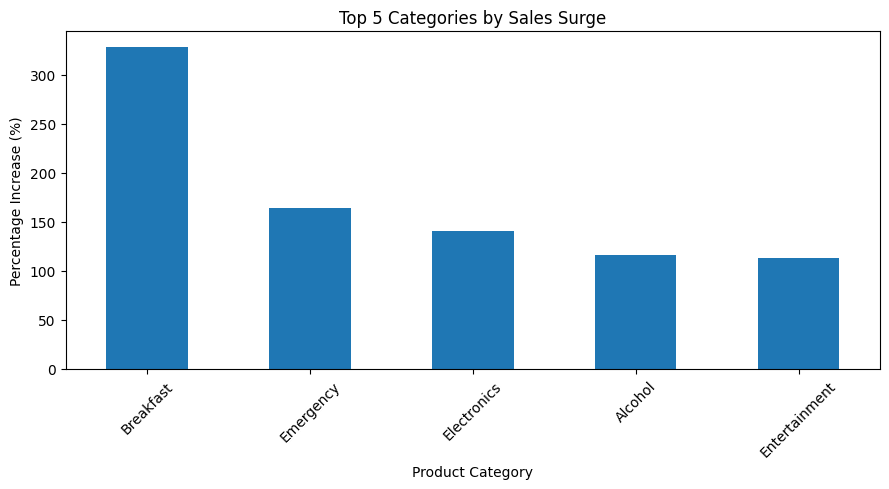

In [99]:
import matplotlib.pyplot as plt

q1_top5 = q1_comparison.head(5)

q1_top5['Percentage Increase'].plot(kind='bar', figsize=(9, 5))

plt.title('Top 5 Categories by Sales Surge')
plt.xlabel('Product Category')
plt.ylabel('Percentage Increase (%)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Explanation:** I made this bar chart to show which five categories had the biggest percentage increases. Breakfast stands out the most, with an increase of over 300%, while the other four categories had increases between about 113% and 164%. The graph makes it easier to see how much more Breakfast sales increased compared to the other categories.

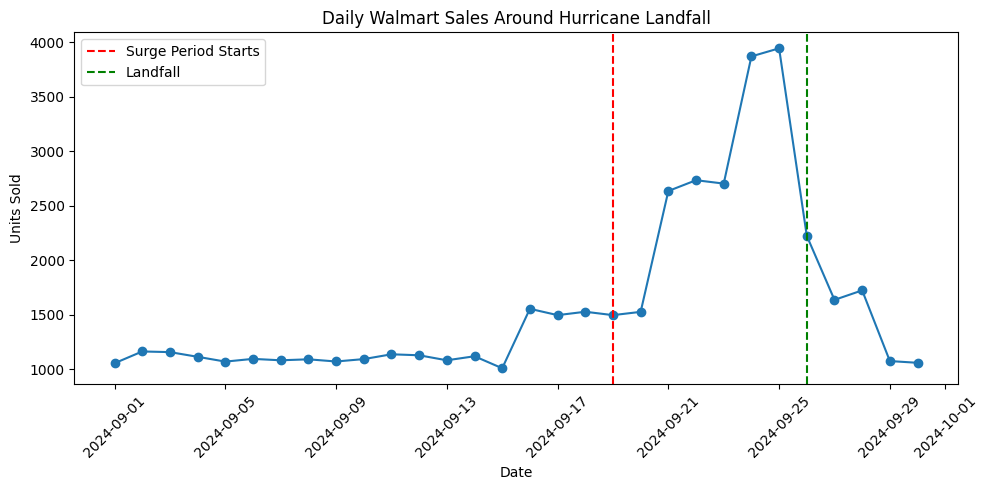

In [102]:
q1_daily = q1_transactions.groupby('transaction_date')['quantity'].sum()

plt.figure(figsize=(10, 5))
plt.plot(q1_daily.index, q1_daily.values, marker='o')

plt.axvline(pd.Timestamp('2024-09-19'), color='red', linestyle='--', label='Surge Period Starts')
plt.axvline(pd.Timestamp('2024-09-26'), color='green', linestyle='--', label='Landfall')

plt.title('Daily Walmart Sales Around Hurricane Landfall')
plt.xlabel('Date')
plt.ylabel('Units Sold')
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

**Explanation:** I wanted to see how sales changed throughout September instead of only comparing the baseline and surge periods. Looking at the graph, sales stayed fairly consistent at the beginning of the month but started increasing around September 15, with a much larger increase around September 20. Sales reached their highest point on September 24 and started dropping the following day, with sales continuing to decrease after landfall. This suggests that customers may have been stocking up on supplies as the hurricane approached. However, some transactions had missing timestamps and negative quantities, which could affect the exact numbers in my results.

## Question 4: Store-Level Geographic Patterns

In [103]:
q4_stores = store_locations_copy.copy()

print("Total stores:", len(q4_stores))
print("Columns:", q4_stores.columns.tolist())
print("Regions:", q4_stores['region'].unique())

q4_stores.head(14)

Total stores: 12
Columns: ['store_id', 'store_name', 'city', 'state', 'zip_code', 'latitude', 'longitude', 'region']
Regions: ['Central' 'West' 'South' 'North' 'East' ' Panhandle' 'Panhandle']


,store_id,store_name,city,state,zip_code,latitude,longitude,region
0,FL-239,Walmart Supercenter Orlando,Orlando,FL,32801,28.5383,-81.3792,Central
1,FL-105,Walmart Supercenter Tampa,Tampa,FL,33602,27.9506,-82.4572,West
2,FL-330,Walmart Supercenter Miami,Miami,FL,33101,25.7617,-80.1918,South
3,FL-412,Walmart Supercenter Jacksonville,Jacksonville,FL,32099,30.3322,-81.6557,North
4,FL-287,Walmart Neighborhood Market Kissimmee,Kissimmee,FL,34741,28.2920,-81.4076,Central
5,FL-156,Walmart Supercenter Daytona Beach,Daytona Beach,FL,32114,29.2108,-81.0228,East
6,FL-501,Walmart Supercenter Fort Myers,Fort Myers,FL,33901,26.6406,-81.8723,West
7,FL-078,Walmart Supercenter Gainesville,Gainesville,FL,32601,29.6516,-82.3248,North
8,FL-619,Walmart Supercenter Tallahassee,Tallahassee,FL,32301,30.4383,-84.2807,Panhandle
9,FL-445,Walmart Supercenter St. Petersburg,St. Petersburg,FL,33701,27.7676,-82.6403,West


In [104]:
q4_stores['store_id'] = q4_stores['store_id'].str.strip().str.upper()
q4_stores['region'] = q4_stores['region'].str.strip().str.title()

q4_transactions = q1_transactions.copy()
q4_transactions['store_id'] = q4_transactions['store_id'].str.strip().str.upper()

print("Regions:", q4_stores['region'].unique())
print("Stores in transactions:", q4_transactions['store_id'].nunique())
print("Stores matched:", q4_transactions['store_id'].isin(q4_stores['store_id']).sum())
print("Total transactions:", len(q4_transactions))

Regions: ['Central' 'West' 'South' 'North' 'East' 'Panhandle']
Stores in transactions: 12
Stores matched: 24648
Total transactions: 24648


**Explanation:** I noticed that some of the store IDs and region names had inconsistent formatting, so I cleaned them by removing extra spaces and making the capitalization consistent. This was important because I needed the store IDs to match correctly when combining the transaction data with the store locations. After cleaning, I found that all 24,648 transactions matched one of the 12 stores.

In [105]:
q4_data = q4_transactions.merge(
    q4_stores[['store_id', 'store_name', 'city', 'region']],
    on='store_id',
    how='left',
    validate='many_to_one'
)

print("Total transactions:", len(q4_data))
print("Missing store locations:", q4_data['store_name'].isna().sum())

q4_data[['transaction_date', 'store_id', 'city', 'region', 'category', 'quantity']].head()

Total transactions: 24648
Missing store locations: 0


,transaction_date,store_id,city,region,category,quantity
0,2024-09-24,FL-710,Pensacola,Panhandle,Grocery,1
1,2024-09-13,FL-412,Jacksonville,North,Grocery,1
2,2024-09-17,FL-105,Tampa,West,Household,2
3,2024-09-11,FL-330,Miami,South,Electronics,1
4,2024-09-26,FL-302,Lakeland,Central,Alcohol,3


**Explanation:** I combined the Walmart transaction data with the store locations table using the store IDs. This allowed me to see which city and region each transaction came from so I could compare demand across different locations. After combining the tables, I checked for missing store locations and found that all 24,648 transactions were matched successfully.

In [106]:
q4_baseline = q4_data[
    q4_data['transaction_date'].between('2024-09-01', '2024-09-18')
]

q4_surge = q4_data[
    q4_data['transaction_date'].between('2024-09-19', '2024-09-25')
]

q4_baseline_avg = q4_baseline.groupby('store_id')['quantity'].sum() / 18
q4_surge_avg = q4_surge.groupby('store_id')['quantity'].sum() / 7

q4_comparison = q4_stores[['store_id', 'city', 'region']].copy()

q4_comparison['Baseline Daily Average'] = q4_comparison['store_id'].map(q4_baseline_avg)
q4_comparison['Surge Daily Average'] = q4_comparison['store_id'].map(q4_surge_avg)

q4_comparison['Percentage Increase'] = (
    (q4_comparison['Surge Daily Average'] - q4_comparison['Baseline Daily Average'])
    / q4_comparison['Baseline Daily Average'] * 100
)

q4_comparison = q4_comparison.sort_values('Percentage Increase', ascending=False)

print(q4_comparison.round(2))

   store_id            city     region  Baseline Daily Average  \
2    FL-330           Miami      South                   95.89   
1    FL-105           Tampa       West                   97.17   
8    FL-619     Tallahassee  Panhandle                   93.56   
10   FL-302        Lakeland    Central                  102.11   
11   FL-710       Pensacola  Panhandle                   97.72   
3    FL-412    Jacksonville      North                   95.61   
5    FL-156   Daytona Beach       East                   98.78   
9    FL-445  St. Petersburg       West                  101.00   
6    FL-501      Fort Myers       West                   96.50   
4    FL-287       Kissimmee    Central                   96.28   
7    FL-078     Gainesville      North                   97.61   
0    FL-239         Orlando    Central                   96.83   

    Surge Daily Average  Percentage Increase  
2                235.14               145.22  
1                231.29               138.03  


**Justification:** I used September 1–18 as the baseline period and September 19–25 as the surge period to keep my analysis consistent with Q1. Since the two periods have different numbers of days, I calculated the average daily units sold at each store instead of comparing the total quantities. This helped me compare how much demand increased at each location. Based on my results, Miami had the highest increase at 145.22%, while Orlando had the lowest at 115.83%.

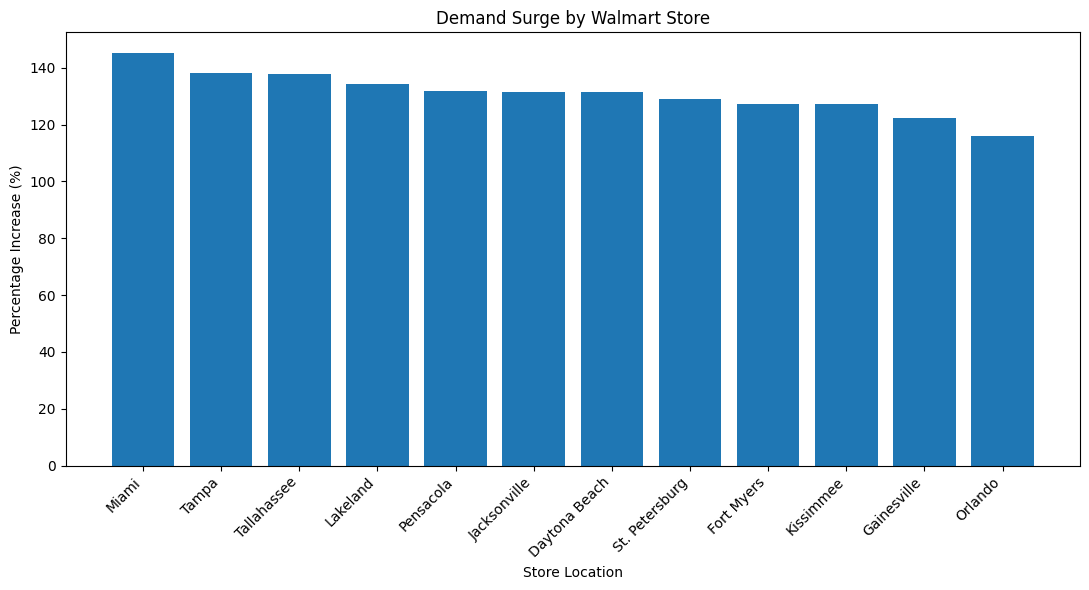

In [107]:
plt.figure(figsize=(11, 6))

plt.bar(q4_comparison['city'], q4_comparison['Percentage Increase'])

plt.title('Demand Surge by Walmart Store')
plt.xlabel('Store Location')
plt.ylabel('Percentage Increase (%)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

**Explanation:** I made this bar chart to compare how much demand increased at each Walmart store before the hurricane. Based on my results, all 12 stores experienced an increase in average daily units sold. Miami had the highest increase at 145.22%, followed by Tampa at 138.03% and Tallahassee at 137.75%. Orlando had the lowest increase at 115.83%. I noticed that demand increased across stores in different parts of Florida, which suggests that hurricane preparation may have affected shopping patterns throughout the state.

In [110]:
q4_region_baseline = q4_baseline.groupby('region')['quantity'].sum() / 18

q4_region_surge = q4_surge.groupby('region')['quantity'].sum() / 7

q4_region_comparison = pd.DataFrame({
    'Baseline Daily Average': q4_region_baseline,
    'Surge Daily Average': q4_region_surge
})

q4_region_comparison['Percentage Increase'] = (
    (q4_region_comparison['Surge Daily Average'] - q4_region_comparison['Baseline Daily Average'])
    / q4_region_comparison['Baseline Daily Average'] * 100
)

q4_region_comparison = q4_region_comparison.sort_values(
    'Percentage Increase', ascending=False
)

print(q4_region_comparison.round(2))

           Baseline Daily Average  Surge Daily Average  Percentage Increase
region                                                                     
South                       95.89               235.14               145.22
Panhandle                  191.28               448.86               134.66
West                       294.67               682.14               131.50
East                        98.78               228.57               131.40
North                      193.22               438.43               126.90
Central                    295.22               667.00               125.93


**Explanation:** I compared the average daily units sold across the different regions of Florida to see if certain areas experienced a larger increase in demand before the hurricane. Based on my results, all six regions had an increase during the surge period. The South region had the highest increase at 145.22%, followed by the Panhandle at 134.66% and West at 131.50%. Central had the lowest increase at 125.93%, although demand still increased there. This suggests that the increase in shopping wasn't limited to one part of Florida, but some regions experienced a larger surge than others.

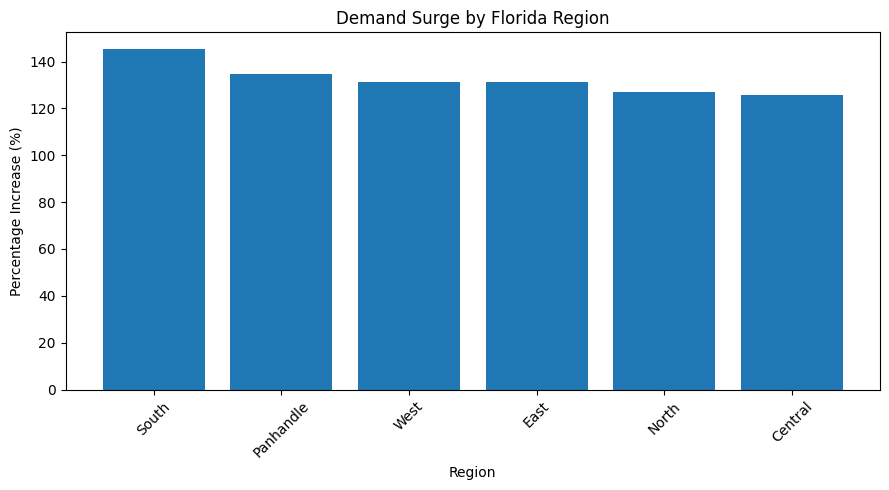

In [112]:
plt.figure(figsize=(9, 5))

plt.bar(
    q4_region_comparison.index,
    q4_region_comparison['Percentage Increase']
)

plt.title('Demand Surge by Florida Region')
plt.xlabel('Region')
plt.ylabel('Percentage Increase (%)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Explanation:** I compared the average daily units sold across the different regions of Florida to see if certain areas experienced a larger increase in demand before the hurricane. Based on my results, all six regions had an increase during the surge period. The South region had the highest increase at 145.22%, followed by the Panhandle at 134.66% and West at 131.50%. Central had the lowest increase at 125.93%, although demand still increased there. I also noticed that some regions had more stores than others, so I kept that in mind when comparing the results. Overall, the increase in shopping wasn't limited to one part of Florida.

##Question 5: Signal vs. Artifact — The Board Games Investigation

In [86]:
#FILTERING SKU WITH ENTERTAINMENT CATEGORY
entertainment_sku = walmart_transactions_copy[walmart_transactions_copy['category']=='Entertainment']
print('skus that are in the entertainment category are: ', entertainment_sku['sku'].unique())
#saving SKU WITH ENTERTAINMENT CATEGORY
entertainment_sku_list = entertainment_sku['sku'].unique().tolist()


skus that are in the entertainment category are:  ['CARDS-01' 'PLAYCARD-STD' 'BG-MONO' 'MONOPOLY-01' 'GAME-MONO']


Explanation: So, in the original walmart transaction table, there are several variants of skus that map to entertainment and I am filtering it because we want to investigate if there was really an increase of entertainment sales during the surge

In [87]:
#Filtering daily sales based on if they are in the entertainment category
entertainment_sales = daily_sales_copy[daily_sales_copy['category']=='Entertainment'].copy()

#Grouping the sales by date to make comparison easier
entertainment_sales_by_dates = entertainment_sales.groupby('date')['total_units'].sum()

#Baseline: We are choosing baseline '2024-09-01' - '2024-09-15' because this is during the normal deman and pre-surge
baseline_sales = entertainment_sales_by_dates.loc['2024-09-01':'2024-09-10']

#Surge: We are choosing '2024-09-23'- '2024-09-25' for the surge as the landfall is on September 26th
surge_sales = entertainment_sales_by_dates.loc['2024-09-23':'2024-09-25']

#Calculate the increase between the baseline period and the surge period
increase = ((surge_sales.mean()-baseline_sales.mean())/baseline_sales.mean())*100

print('average entertainment units sold during basline period :', baseline_sales.mean())

print('average entertainment units sold during sure period :', surge_sales.mean())

print('Percentage change :', increase,"%")

average entertainment units sold during basline period : 559.65
average entertainment units sold during sure period : 1816.5
Percentage change : 224.57786116322703 %


Justification: Based on the changes in sales during the pre-surge period and the surge period, there has been an increase of 224.6%. The pre-surge period i choose is [...] because this oeriod was noted as the "normal" phase. Since the landfall was predicted to happen on the 26th of September, I choose the dates 2024-09-23 to 2024-09-25 because they were denoted as the surge period in the last checkpoint. One thing to note is that the increase depends on how the pre-surge and surge time are set. However, overall there have been an increase of about 200%.

**Cross referencing the daily summaries and walmart transaction for entertainment category**

In [88]:
entertainment_transaction = walmart_transactions_copy[walmart_transactions_copy['category']=='Entertainment'].copy()

entertainment_transaction_by_date = entertainment_transaction.groupby('transaction_date')['quantity'].sum()

baseline_transactions = entertainment_transaction_by_date.loc['2024-09-01':'2024-09-10']

surge_transactions =  entertainment_transaction_by_date.loc['2024-09-23': '2024-09-25']

increase = ((surge_transactions.mean()-baseline_transactions.mean())/baseline_transactions.mean())*100

print('basline transactions average for entertainment supplies before the surge:', baseline_transactions.mean())
print('surge transactions average for entertainment supplies during the surge:', surge_transactions.mean())
print('increase', increase,"%")

basline transactions average for entertainment supplies before the surge: 102.4
surge transactions average for entertainment supplies during the surge: 302.0
increase 194.92187499999997 %


In [89]:
comparison = pd.DataFrame({
    'Daily sales units' : entertainment_sales_by_dates,
    'Walmart transactions units': entertainment_transaction_by_date
})

comparison_pre_surge = comparison.loc['2024-09-01':'2024-09-10'].copy()
comparison_surge = comparison.loc['2024-09-23':'2024-09-25'].copy()

print('DIFFERENCE OF ENTERTAINMENT UNITS SOLD BEFORE SURGE PERIOD IN WALMART TRANSACTION AND DAILY SALES')
comparison_pre_surge['Difference'] = (comparison_pre_surge['Daily sales units'] - comparison_pre_surge['Walmart transactions units'])
print(comparison_pre_surge)

print('DIFFERENCE OF ENTERTAINMENT UNITS SOLD DURING SURGE PERIOD IN WALMART TRANSACTION AND DAILY SALES')
comparison_surge['Difference'] = (comparison_surge['Daily sales units'] - comparison_surge['Walmart transactions units'])
print(comparison_surge)

DIFFERENCE OF ENTERTAINMENT UNITS SOLD BEFORE SURGE PERIOD IN WALMART TRANSACTION AND DAILY SALES
            Daily sales units  Walmart transactions units  Difference
2024-09-01              544.0                          99       445.0
2024-09-02              498.0                          93       405.0
2024-09-03              504.0                         104       400.0
2024-09-04              600.5                          95       505.5
2024-09-05              551.0                          99       452.0
2024-09-06              464.0                         101       363.0
2024-09-07              624.0                         112       512.0
2024-09-08              622.0                         114       508.0
2024-09-09              613.0                         105       508.0
2024-09-10              576.0                         102       474.0
DIFFERENCE OF ENTERTAINMENT UNITS SOLD DURING SURGE PERIOD IN WALMART TRANSACTION AND DAILY SALES
            Daily sales units  Wal

Explanation: Both the daily summary and walmart transactions table show that there is an significant increase in the Entertainment sales before the landfall. The daily sales table shows an increase in Entertainment sales of about 224% and the walmart transaction show and increase in Entertainment sales of about 195%.42%. However, in the code above, it is visible that the total units sold by the two sources differ and that walmart transactions show a smaller increase. Missing timestmaps in the transaction table and negative units(returns) may contribute to this result.

**Cross referencing the daily summaries and walmart transaction for entertainment category with the entertainment inventory**

In [90]:
#filter inventory for entertainment category
entertainment_inventory = inventory_copy[inventory_copy['sku'].isin(entertainment_sku_list)].copy()

#filter record by pre-surge dates
entertainment_inventory_pre_surge = entertainment_inventory[(entertainment_inventory['date']>='2024-09-05')&(entertainment_inventory['date']<='2024-09-10')].copy()

#adding a colum 'units_on_hand_lower_than_reorder_point' to see how many times the inventory was low on stocks
entertainment_inventory_pre_surge['units_on_hand_lower_than_reorder_point'] = (entertainment_inventory_pre_surge['units_on_hand']< entertainment_inventory_pre_surge['reorder_point'])

#filter record by pre-surge dates
entertainment_inventory_surge = entertainment_inventory[(entertainment_inventory['date']>='2024-09-23')&(entertainment_inventory['date']<='2024-09-25')].copy()

#adding a colum 'units_on_hand_lower_than_reorder_point' to see how many times the inventory was low on stocks
entertainment_inventory_surge['units_on_hand_lower_than_reorder_point'] = entertainment_inventory_surge['units_on_hand']< entertainment_inventory_surge['reorder_point']


In [91]:
from numpy import mean
inventory_entertainment_summary_pre_surge = entertainment_inventory_pre_surge.groupby('sku').agg(
    mean_units_on_hand = ('units_on_hand','mean'),
    mean_reorder_point = ('reorder_point','mean'),
    count_low_stock = ('units_on_hand_lower_than_reorder_point','sum'),
    total_units =('sku','size')
)

inventory_entertainment_summary_surge = entertainment_inventory_surge.groupby('sku').agg(
    mean_units_on_hand = ('units_on_hand','mean'),
    mean_reorder_point = ('reorder_point','mean'),
    count_low_stock = ('units_on_hand_lower_than_reorder_point','sum'),
    total_units =('sku','size')
)

In [92]:
print('ENTERTAINMENT INVENTORY BEFORE SURGE: ')
inventory_entertainment_summary_pre_surge

ENTERTAINMENT INVENTORY BEFORE SURGE: 


,mean_units_on_hand,mean_reorder_point,count_low_stock,total_units
sku,,,,
BG-MONO,64.000000,37.611111,3,18
CARDS-01,56.500000,33.437500,6,16
GAME-MONO,55.409091,35.318182,9,22
MONOPOLY-01,77.277778,31.388889,1,18
PLAYCARD-STD,64.769231,34.000000,2,13


In [93]:
print('ENTERTAINMENT INVENTORY DURING SURGE: ')
inventory_entertainment_summary_surge

ENTERTAINMENT INVENTORY DURING SURGE: 


,mean_units_on_hand,mean_reorder_point,count_low_stock,total_units
sku,,,,
BG-MONO,37.909091,34.909091,3,11
CARDS-01,28.727273,37.181818,7,11
GAME-MONO,33.250000,31.666667,6,12
MONOPOLY-01,35.285714,39.428571,4,7
PLAYCARD-STD,40.857143,35.000000,3,7


Explanation:The summary above shows that during the surge the average units on hand dramastically decreased than the average unit on hand cross more than half of the entertainment products. These findings definitely suggest that several entertainment products experienced lower inventory available and higher pressure for demnand. Based on all the analysis, we can confirm that the stores should stock up on board games/entertainment supplies before the next storm

##Visualisation on how many entertainment supplies were sold during pre-surge and surge period

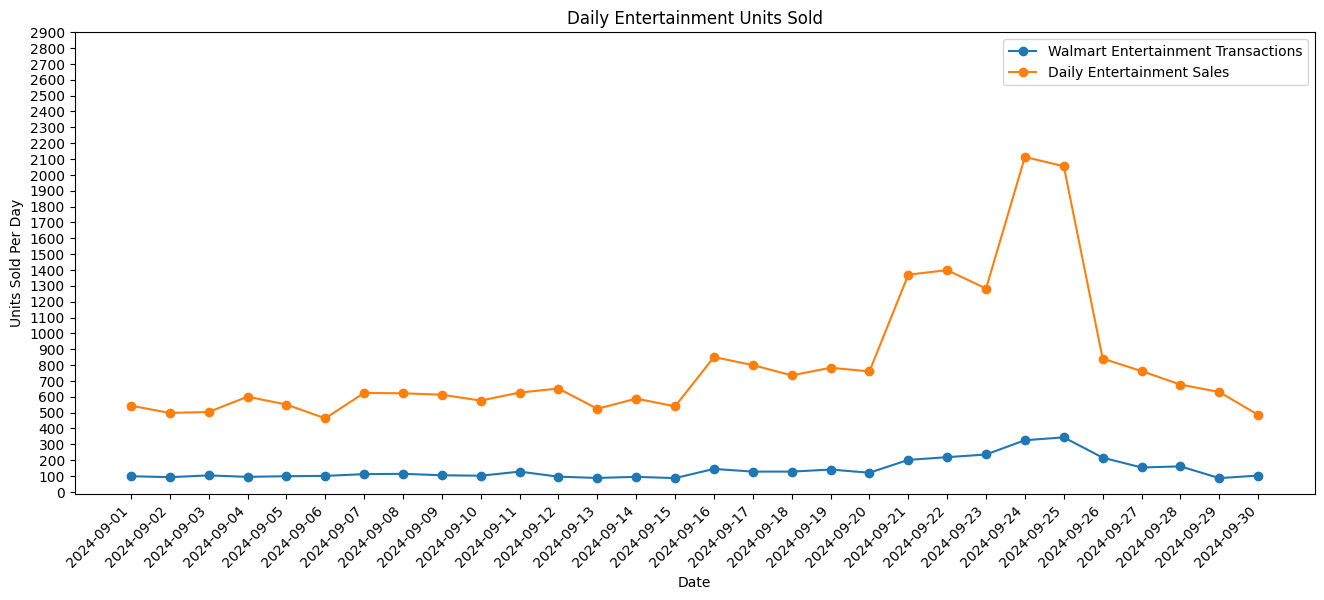

In [94]:
import matplotlib.pyplot as plt

entertainment_comparison= pd.DataFrame({
    'Daily Entertainment Sales': entertainment_sales_by_dates,
    'Walmart Transactions': entertainment_transaction_by_date
})

entertainment_comparison.index = pd.to_datetime(entertainment_comparison.index)
entertainment_comparison = entertainment_comparison.sort_index()

entertainment_comparison.head()

plt.figure(figsize=(16, 6))
plt.plot(
    entertainment_comparison.index,
    entertainment_comparison['Walmart Transactions'],
    marker = 'o',
    label = 'Walmart Entertainment Transactions'
)

plt.plot(
    entertainment_comparison.index,
    entertainment_comparison['Daily Entertainment Sales'],
    marker = 'o',
    label = 'Daily Entertainment Sales'
)

plt.xlabel('Date')
plt.xticks(entertainment_comparison.index, rotation=45, ha='right')
plt.ylabel('Units Sold Per Day')
plt.yticks(range(0, 3000, 100))
plt.title('Daily Entertainment Units Sold')
plt.legend()

##Visualization on Units on Hands vs Reorder points during pre-surge and during surge period

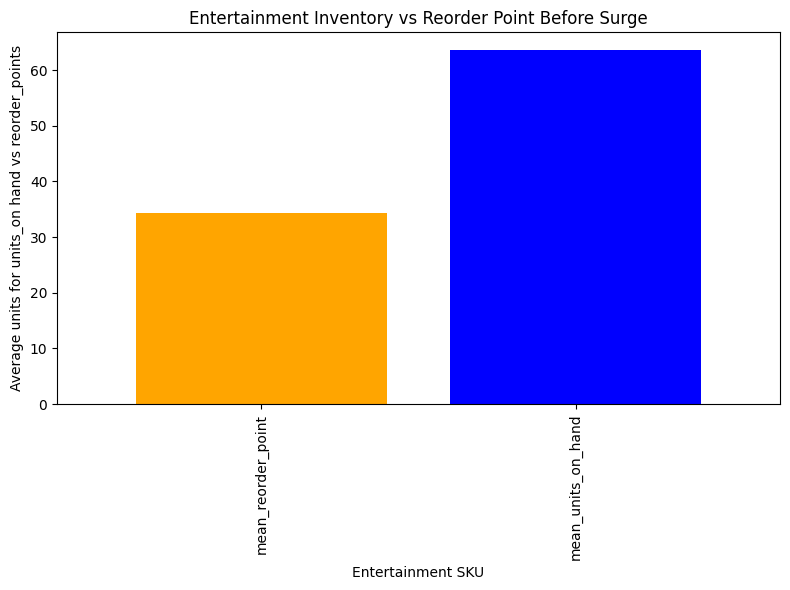

Text(0.5, 1.0, 'Entertainment Inventory vs Reorder Point during Surge')

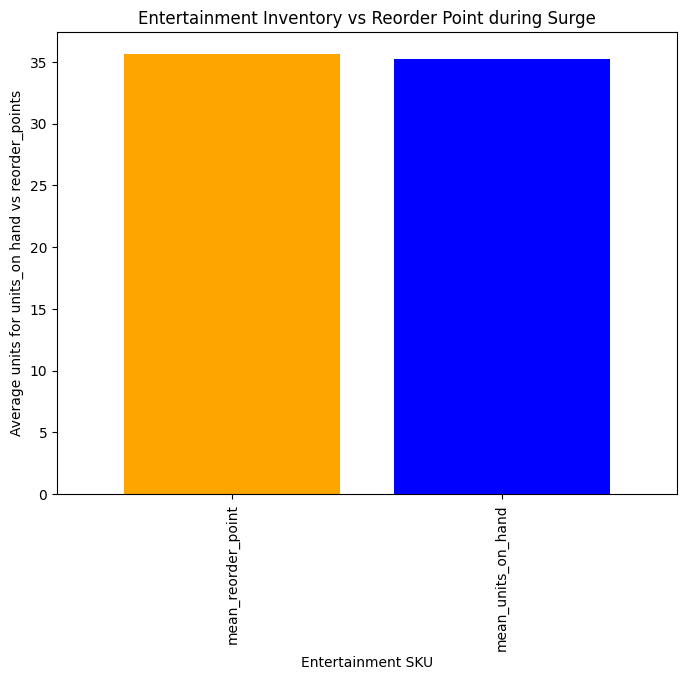

In [95]:
inventory_entertainment_summary_pre_surge[['mean_reorder_point','mean_units_on_hand']].mean().plot(kind='bar',figsize=(8,6),width=0.8,color=['orange','blue'])

plt.xlabel('Entertainment SKU')
plt.ylabel('Average units for units_on hand vs reorder_points')
plt.title('Entertainment Inventory vs Reorder Point Before Surge')
plt.tight_layout()
plt.show()


inventory_entertainment_summary_surge[['mean_reorder_point','mean_units_on_hand']].mean().plot(kind='bar',figsize=(8,6),width=0.8,color=['orange','blue'])

plt.xlabel('Entertainment SKU')
plt.ylabel('Average units for units_on hand vs reorder_points')
plt.title('Entertainment Inventory vs Reorder Point during Surge')

**Justification:** Both the daily summary and walmart transactions table show that there is an significant increase in the Entertainment sales before the landfall. The daily sales table shows an increase in Entertainment sales of about 219.54% and the walmart transaction show and increase in Entertainment sales of about 198.42%. However, in the code above, it is visible that the total units sold by the two sources differ. Missing timestmaps and negative units(returns) may contribute to this result. These data inconsistensies can contribute in the different amounts of increase in the entertainment sales. Also, according to the inventory data, we can see that during the surge, there have been several occurences where the unit on had was greater than the reorder point for entertainment products. It is advisable to stock up on board and card games to not fall under the reprder point. The data suggests that boardgames and card games are considered in the netertainment sector.